In [ ]:
# SETUP MANDIRI: menyiapkan folder, kode src/, dan dataset (SEED 1083) bila sesi baru
import os, sys, subprocess
ROOT = "/content/simuteh-2330511083"
for d in ["data/sintetis", "notebook", "src", "hasil", "laporan"]:
    os.makedirs(f"{ROOT}/{d}", exist_ok=True)
FILES = {'src/utils_cv.py': '"""utils_cv.py: fungsi bantu yang dipakai ulang sepanjang semester."""\nimport cv2\nimport numpy as np\nimport matplotlib.pyplot as plt\n\n\ndef baca(path):\n    """Membaca citra dan langsung memberi pesan jelas bila gagal."""\n    img = cv2.imread(path)\n    if img is None:\n        raise FileNotFoundError(f"Citra tidak ditemukan: {path}")\n    return img\n\n\ndef tampil(daftar, judul, baris=1, ukuran=(14, 4)):\n    """Menampilkan beberapa citra berdampingan. Citra 3 kanal dianggap BGR."""\n    kolom = int(np.ceil(len(daftar) / baris))\n    plt.figure(figsize=ukuran)\n    for i, (im, jd) in enumerate(zip(daftar, judul)):\n        plt.subplot(baris, kolom, i + 1)\n        if im.ndim == 3:\n            plt.imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB))\n        else:\n            plt.imshow(im, cmap="gray", vmin=0, vmax=255)\n        plt.title(jd)\n        plt.axis("off")\n    plt.tight_layout()\n\n\ndef kontras_bercak(kanal, mask_daun, mask_bercak):\n    """KB = |rerata bercak - rerata daun sehat| / simpangan baku daun sehat."""\n    k = kanal.astype(np.float64)\n    sehat = (mask_daun > 0) & (mask_bercak == 0)\n    bercak = mask_bercak > 0\n    if bercak.sum() == 0:\n        return float("nan")\n    return abs(k[bercak].mean() - k[sehat].mean()) / (k[sehat].std() + 1e-6)\n\n\ndef statistik(gray):\n    """Ringkasan statistik intensitas untuk mendiagnosis mutu citra."""\n    return {"rerata": round(float(gray.mean()), 1),\n            "simpangan_baku": round(float(gray.std()), 1),\n            "min": int(gray.min()), "maks": int(gray.max()),\n            "persen_gelap": round(100 * float((gray < 50).mean()), 1),\n            "persen_terang": round(100 * float((gray > 205).mean()), 1)}', 'src/buat_dataset_sintetis.py': '"""\nbuat_dataset_sintetis.py\nMembangkitkan dataset citra sintetis daun teh untuk studi kasus SIMUTEH.\n"""\nimport os\nimport csv\nimport cv2\nimport numpy as np\n\nSEED = 1083          # 4 digit terakhir NIM 2330511083\nN_PER_KELAS = 20\nH, W = 480, 640\nKELAS = ["sehat", "ringan", "berat"]\nKONDISI = ["normal", "gelap", "terang", "kontras_rendah", "bayangan"]\nOUT = os.path.join("data", "sintetis")\nrng = np.random.default_rng(SEED)\n\n\ndef gambar_daun(img, mask):\n    """Menggambar satu helai daun berbentuk elips beserta tulang daunnya."""\n    cx = int(rng.integers(260, 380))\n    cy = int(rng.integers(200, 280))\n    ax = int(rng.integers(190, 240))\n    ay = int(rng.integers(95, 125))\n    sudut = float(rng.uniform(-25, 25))\n    hijau = np.array([rng.integers(35, 60), rng.integers(120, 150),\n                      rng.integers(45, 75)])  # BGR\n    cv2.ellipse(img, (cx, cy), (ax, ay), sudut, 0, 360, hijau.tolist(), -1)\n    cv2.ellipse(mask, (cx, cy), (ax, ay), sudut, 0, 360, 255, -1)\n    # tulang daun utama dan cabang\n    t = np.deg2rad(sudut)\n    p1 = (int(cx - ax * np.cos(t)), int(cy - ax * np.sin(t)))\n    p2 = (int(cx + ax * np.cos(t)), int(cy + ax * np.sin(t)))\n    tulang = (hijau * 1.35).clip(0, 255).tolist()\n    cv2.line(img, p1, p2, tulang, 3)\n    for k in np.linspace(-0.7, 0.7, 6):\n        bx, by = cx + k * ax * np.cos(t), cy + k * ax * np.sin(t)\n        for arah in (-1, 1):\n            ex = bx + 0.35 * ax * np.cos(t + arah * 1.0)\n            ey = by + 0.35 * ax * np.sin(t + arah * 1.0)\n            cv2.line(img, (int(bx), int(by)), (int(ex), int(ey)), tulang, 1)\n    return mask\n\n\ndef gambar_bercak(img, mask_daun, mask_bercak, kelas):\n    """Menambahkan bercak cacar daun (pucat kekuningan, tepi kecokelatan)."""\n    if kelas == "sehat":\n        return\n    n = int(rng.integers(1, 4)) if kelas == "ringan" else int(rng.integers(6, 13))\n    r_min, r_maks = (3, 7) if kelas == "ringan" else (5, 14)\n    ys, xs = np.where(mask_daun > 0)\n    for _ in range(n):\n        i = int(rng.integers(0, len(xs)))\n        r = int(rng.integers(r_min, r_maks + 1))\n        pusat = (int(xs[i]), int(ys[i]))\n        warna = [int(rng.integers(70, 100)), int(rng.integers(165, 190)),\n                 int(rng.integers(185, 210))]  # BGR pucat\n        cv2.circle(img, pusat, r + 2, (40, 80, 110), -1)  # tepi cokelat\n        cv2.circle(img, pusat, r, warna, -1)\n        cv2.circle(mask_bercak, pusat, r + 2, 255, -1)\n    mask_bercak &= mask_daun  # bercak hanya di daun\n\n\ndef ganggu_cahaya(img, kondisi):\n    """Mensimulasikan kondisi pemotretan di lapangan."""\n    f = img.astype(np.float32)\n    if kondisi == "gelap":\n        f = 255 * (f / 255) ** 2.0\n    elif kondisi == "terang":\n        f = 255 * (f / 255) ** 0.45\n    elif kondisi == "kontras_rendah":\n        f = 0.35 * f + 95\n    elif kondisi == "bayangan":\n        gx = np.linspace(1.15, 0.30, W, dtype=np.float32)  # separuh teduh\n        f = f * gx[None, :, None]\n    sigma = float(rng.uniform(6, 14))\n    f = f + rng.normal(0, sigma, f.shape)  # derau sensor\n    return np.clip(f, 0, 255).astype(np.uint8)\n\n\ndef main():\n    for sub in ["citra", "bersih", "mask_daun", "mask_bercak"]:\n        os.makedirs(os.path.join(OUT, sub), exist_ok=True)\n    baris = []\n    nomor = 0\n    for kelas in KELAS:\n        for j in range(N_PER_KELAS):\n            nomor += 1\n            latar = np.array([rng.integers(150, 190), rng.integers(170, 205),\n                              rng.integers(185, 215)])  # nampan anyaman\n            img = np.ones((H, W, 3), np.uint8) * latar.astype(np.uint8)\n            img = cv2.add(img, rng.integers(0, 12, (H, W, 3)).astype(np.uint8))\n            m_daun = np.zeros((H, W), np.uint8)\n            m_bercak = np.zeros((H, W), np.uint8)\n            gambar_daun(img, m_daun)\n            gambar_bercak(img, m_daun, m_bercak, kelas)\n            bersih = cv2.GaussianBlur(img, (3, 3), 0.8)\n            kondisi = KONDISI[j % len(KONDISI)]\n            citra = ganggu_cahaya(bersih, kondisi)\n            nama = f"teh_{nomor:03d}.png"\n            cv2.imwrite(os.path.join(OUT, "citra", nama), citra)\n            cv2.imwrite(os.path.join(OUT, "bersih", nama), bersih)\n            cv2.imwrite(os.path.join(OUT, "mask_daun", nama), m_daun)\n            cv2.imwrite(os.path.join(OUT, "mask_bercak", nama), m_bercak)\n            persen = 100 * (m_bercak > 0).sum() / max((m_daun > 0).sum(), 1)\n            baris.append([nama, kelas, kondisi, round(persen, 2)])\n    with open(os.path.join(OUT, "label.csv"), "w", newline="") as f:\n        w = csv.writer(f)\n        w.writerow(["nama_file", "kelas", "kondisi_cahaya", "persen_bercak"])\n        w.writerows(baris)\n    print(f"Selesai: {nomor} citra tersimpan di {OUT}")\n\n\nif __name__ == "__main__":\n    main()', 'src/praproses.py': '"""praproses.py: rangkaian praproses SIMUTEH (dipakai ulang mulai P5)."""\nimport json\nimport cv2\nimport numpy as np\n\nPARAM_BAWAAN = {\n    "lebar": 640,        # sampling: lebar citra kerja (piksel)\n    "gamma": 1.0,        # < 1 mencerahkan, > 1 menggelapkan\n    "clahe_clip": 2.0,   # 0 berarti CLAHE tidak dipakai\n    "clahe_tile": 8,\n    "penapis": "median", # "none", "rerata", "gaussian", "median"\n    "kernel": 3,\n    "sigma": 1.0,\n    "tajam_k": 0.0,      # 0 berarti tanpa penajaman\n}\n\ndef praproses(img_bgr, p=None):\n    """Urutan: ubah ukuran -> gamma -> CLAHE kanal V -> redam derau -> tajamkan."""\n    p = {**PARAM_BAWAAN, **(p or {})}\n\n    # 1. Ubah ukuran: lebar = p["lebar"], rasio aspek tetap, INTER_AREA\n    h, w = img_bgr.shape[:2]\n    tinggi = int(round(h * p["lebar"] / w))\n    img = cv2.resize(img_bgr, (p["lebar"], tinggi), interpolation=cv2.INTER_AREA)\n\n    # 2. Koreksi gamma lewat tabel LUT (hanya bila gamma != 1)\n    if p["gamma"] != 1:\n        lut = np.array([255 * (i / 255) ** p["gamma"] for i in range(256)])\n        img = cv2.LUT(img, lut.clip(0, 255).astype(np.uint8))\n\n    # 3. CLAHE hanya pada kanal V (HSV), lalu kembali ke BGR\n    if p["clahe_clip"] > 0:\n        clahe = cv2.createCLAHE(clipLimit=p["clahe_clip"],\n                                tileGridSize=(p["clahe_tile"], p["clahe_tile"]))\n        hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)\n        hsv[:, :, 2] = clahe.apply(hsv[:, :, 2])\n        img = cv2.cvtColor(hsv, cv2.COLOR_HSV2BGR)\n\n    # 4. Redam derau (ukuran kernel harus ganjil)\n    k = int(p["kernel"])\n    if p["penapis"] == "rerata":\n        img = cv2.blur(img, (k, k))\n    elif p["penapis"] == "gaussian":\n        img = cv2.GaussianBlur(img, (k, k), p["sigma"])\n    elif p["penapis"] == "median":\n        img = cv2.medianBlur(img, k)\n    # "none": tidak melakukan apa-apa\n\n    # 5. Unsharp masking: citra + k * (citra - blur)\n    if p["tajam_k"] > 0:\n        blur = cv2.GaussianBlur(img, (5, 5), 1.0)\n        img = cv2.addWeighted(img, 1 + p["tajam_k"], blur, -p["tajam_k"], 0)\n\n    return img\n\ndef simpan_param(p, path="../hasil/param_praproses.json"):\n    with open(path, "w") as f:\n        json.dump({**PARAM_BAWAAN, **p}, f, indent=2)'}
for p, t in FILES.items():
    if not os.path.exists(f"{ROOT}/{p}"):
        open(f"{ROOT}/{p}", "w").write(t)
os.chdir(ROOT)
if not os.path.exists("data/sintetis/label.csv"):
    print(subprocess.run([sys.executable, "src/buat_dataset_sintetis.py"], capture_output=True, text=True).stdout)
os.chdir(f"{ROOT}/notebook")


In [123]:
# === B3 ===
%cd /content/simuteh-2330511083/notebook
import sys
sys.path.append("../src")
import cv2, numpy as np, pandas as pd, matplotlib.pyplot as plt
from utils_cv import baca, tampil, kontras_bercak, statistik

/content/simuteh-2330511083/notebook


teh_041.png {'rerata': 178.5, 'simpangan_baku': 39.2, 'min': 71, 'maks': 225, 'persen_gelap': 0.0, 'persen_terang': 12.3}
teh_042.png {'rerata': 136.6, 'simpangan_baku': 50.3, 'min': 6, 'maks': 202, 'persen_gelap': 15.6, 'persen_terang': 0.0}
teh_043.png {'rerata': 209.3, 'simpangan_baku': 21.9, 'min': 145, 'maks': 246, 'persen_gelap': 0.0, 'persen_terang': 75.3}
teh_044.png {'rerata': 157.7, 'simpangan_baku': 14.0, 'min': 110, 'maks': 190, 'persen_gelap': 0.0, 'persen_terang': 0.0}
teh_045.png {'rerata': 125.8, 'simpangan_baku': 52.8, 'min': 28, 'maks': 243, 'persen_gelap': 1.1, 'persen_terang': 9.5}


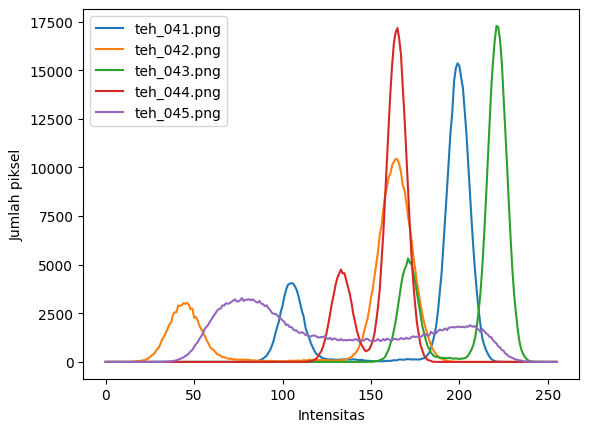

In [124]:
for nama in ["teh_041.png", "teh_042.png", "teh_043.png",
             "teh_044.png", "teh_045.png"]:
    gray = cv2.cvtColor(baca(f"../data/sintetis/citra/{nama}"),
                        cv2.COLOR_BGR2GRAY)
    print(nama, statistik(gray))
    hist = cv2.calcHist([gray], [0], None, [256], [0, 256])
    plt.plot(hist, label=nama)
plt.xlabel("Intensitas"); plt.ylabel("Jumlah piksel"); plt.legend()
plt.savefig("../hasil/b3_histogram_5kondisi.png"); plt.show()

In [125]:
for i in range(21, 26):
    nama = f"teh_{i:03d}.png"
    gray = cv2.cvtColor(baca(f"../data/sintetis/citra/{nama}"), cv2.COLOR_BGR2GRAY)
    print(nama, statistik(gray))

teh_021.png {'rerata': 176.9, 'simpangan_baku': 37.4, 'min': 74, 'maks': 236, 'persen_gelap': 0.0, 'persen_terang': 11.2}
teh_022.png {'rerata': 126.7, 'simpangan_baku': 45.7, 'min': 12, 'maks': 193, 'persen_gelap': 15.6, 'persen_terang': 0.0}
teh_023.png {'rerata': 205.6, 'simpangan_baku': 27.0, 'min': 125, 'maks': 252, 'persen_gelap': 0.0, 'persen_terang': 74.1}
teh_024.png {'rerata': 153.1, 'simpangan_baku': 14.4, 'min': 106, 'maks': 190, 'persen_gelap': 0.0, 'persen_terang': 0.0}
teh_025.png {'rerata': 123.5, 'simpangan_baku': 53.6, 'min': 23, 'maks': 242, 'persen_gelap': 1.9, 'persen_terang': 8.9}


rmin, rmax (persentil 2 dan 98): 53.0 220.0
asli       KB=1.77 sigma=52.8
negatif    KB=1.77 sigma=52.8
cerah+50   KB=1.77 sigma=51.2
kontras    KB=1.77 sigma=74.5
regang     KB=1.83 sigma=80.1
gamma0.5   KB=1.58 sigma=37.7
gamma1.8   KB=2.11 sigma=57.3
ekualisasi KB=1.41 sigma=73.4
CLAHE      KB=2.18 sigma=45.1


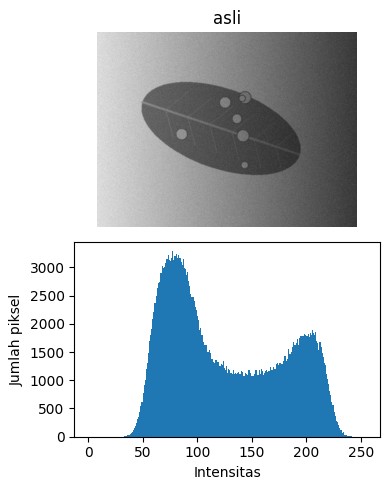

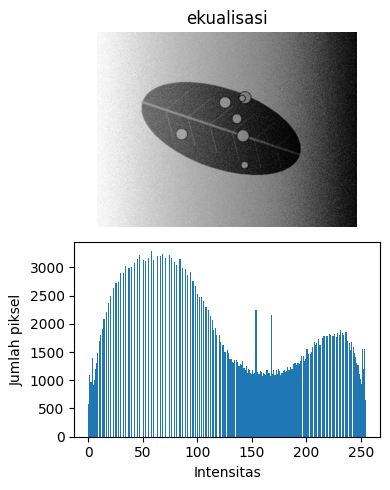

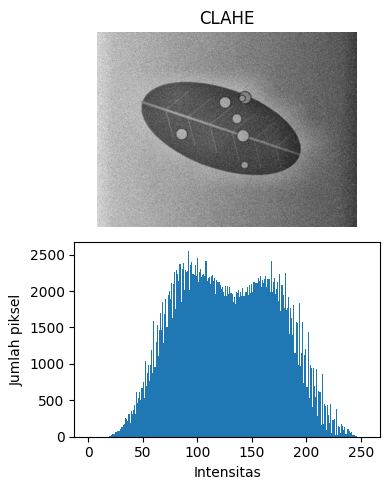

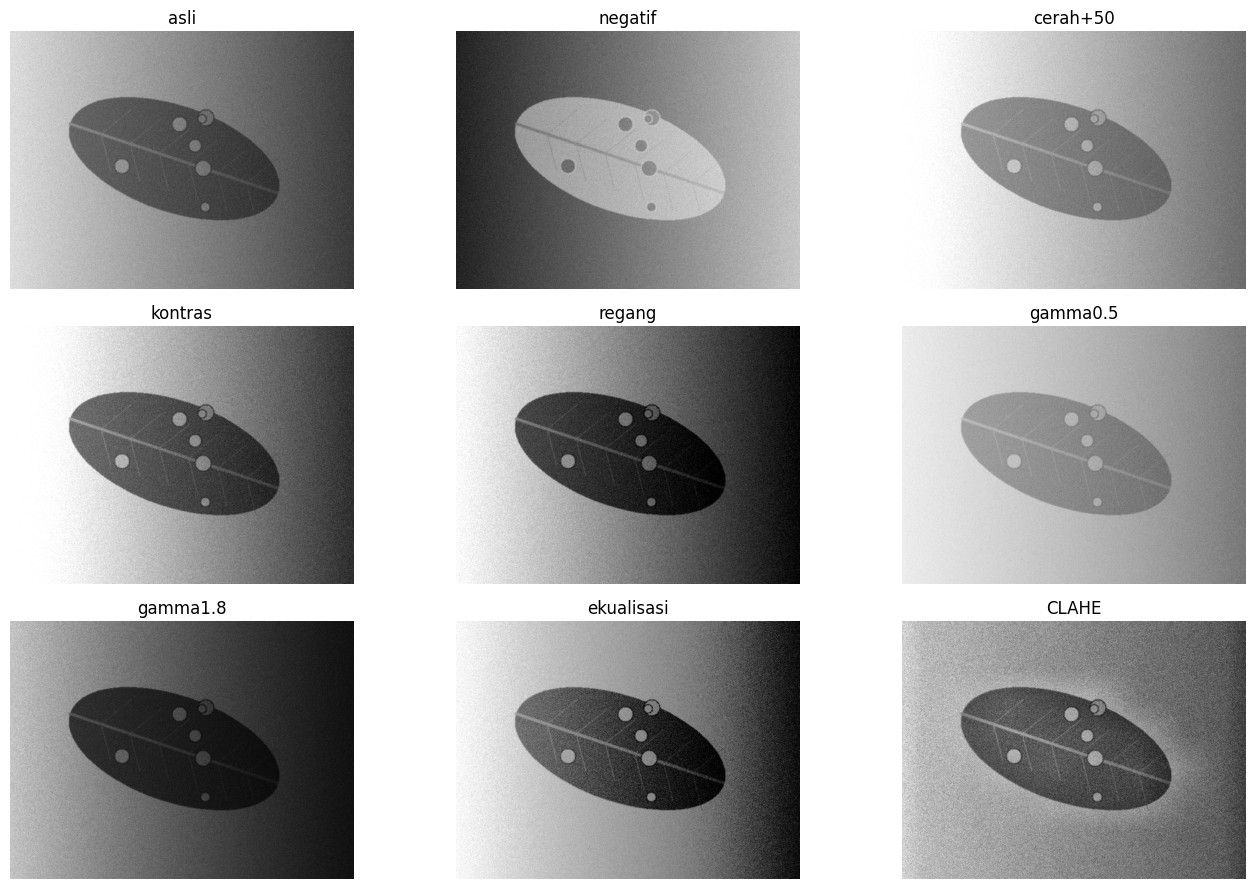

In [126]:
nama = "teh_045.png"
img = baca(f"../data/sintetis/citra/{nama}")
md = cv2.imread(f"../data/sintetis/mask_daun/{nama}", 0)
mb = cv2.imread(f"../data/sintetis/mask_bercak/{nama}", 0)
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

def gamma_lut(g):
    lut = np.array([255 * (i / 255) ** g for i in range(256)])
    return lut.clip(0, 255).astype(np.uint8)

rmin, rmax = np.percentile(gray, (2, 98))
hasil = {
    "asli": gray,
    "negatif": 255 - gray,
    "cerah+50": cv2.add(gray, 50),
    "kontras": cv2.convertScaleAbs(gray, alpha=1.5, beta=-40),
    "regang": np.clip((gray - rmin) / (rmax - rmin) * 255, 0, 255).astype(np.uint8),
    "gamma0.5": cv2.LUT(gray, gamma_lut(0.5)),
    "gamma1.8": cv2.LUT(gray, gamma_lut(1.8)),
    "ekualisasi": cv2.equalizeHist(gray),
    "CLAHE": cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8)).apply(gray),
}
print("rmin, rmax (persentil 2 dan 98):", rmin, rmax)
for nm, c in hasil.items():
    print(f"{nm:10s} KB={kontras_bercak(c, md, mb):.2f} sigma={c.std():.1f}")

# tampilan citra + histogram (tata letak Gambar 4)
for nm in ["asli", "ekualisasi", "CLAHE"]:
    c = hasil[nm]
    fig, ax = plt.subplots(2, 1, figsize=(4, 5))
    ax[0].imshow(c, cmap="gray", vmin=0, vmax=255); ax[0].axis("off")
    ax[0].set_title(nm)
    ax[1].hist(c.ravel(), bins=256, range=(0, 255))
    ax[1].set_xlabel("Intensitas"); ax[1].set_ylabel("Jumlah piksel")
    plt.tight_layout(); plt.savefig(f"../hasil/b3_{nm}.png"); plt.show()

tampil(list(hasil.values()), list(hasil.keys()), baris=3, ukuran=(14, 9))
plt.savefig("../hasil/b3_panel_metode.png"); plt.show()

clip=1.0 tile=4: KB=2.51
clip=1.0 tile=8: KB=2.31
clip=1.0 tile=16: KB=2.18
clip=2.0 tile=4: KB=2.50
clip=2.0 tile=8: KB=2.18
clip=2.0 tile=16: KB=2.07
clip=4.0 tile=4: KB=2.22
clip=4.0 tile=8: KB=1.85
clip=4.0 tile=16: KB=1.70


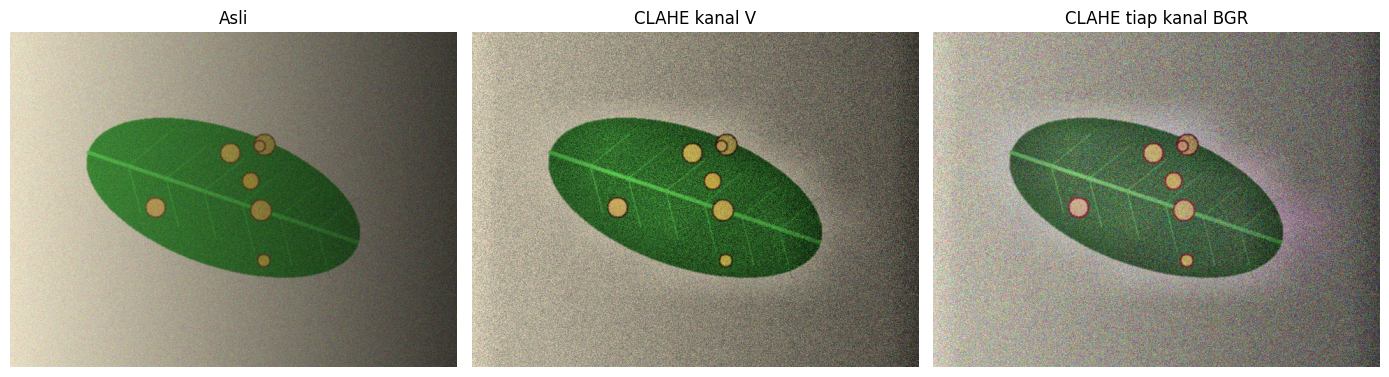

In [127]:
for clip in [1.0, 2.0, 4.0]:
    for tile in [4, 8, 16]:
        c = cv2.createCLAHE(clipLimit=clip,
                            tileGridSize=(tile, tile)).apply(gray)
        print(f"clip={clip} tile={tile}: KB={kontras_bercak(c, md, mb):.2f}")

clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
hsv[:, :, 2] = clahe.apply(hsv[:, :, 2])
via_v = cv2.cvtColor(hsv, cv2.COLOR_HSV2BGR)
via_bgr = cv2.merge([clahe.apply(c) for c in cv2.split(img)])
tampil([img, via_v, via_bgr], ["Asli", "CLAHE kanal V", "CLAHE tiap kanal BGR"])
plt.savefig("../hasil/b3_clahe_warna.png"); plt.show()

metode          CLAHE  asli  ekualisasi  gamma0.5  gamma0.7  gamma1.5  \
kondisi                                                                 
bayangan         1.58  1.52        1.23      1.36      1.42      1.69   
gelap            1.88  3.45        0.84      2.70      2.98      4.35   
kontras_rendah   1.36  1.74        1.59      1.68      1.70      1.81   
terang           1.34  2.61        1.33      2.46      2.53      2.74   

metode          gamma1.8  regang  
kondisi                           
bayangan            1.78    1.57  
gelap               4.93    3.71  
kontras_rendah      1.82    1.87  
terang              2.82    2.81  

Usulan metode per kondisi: {'bayangan': 'gamma1.8', 'gelap': 'gamma1.8', 'kontras_rendah': 'regang', 'terang': 'gamma1.8'}
gelap           teh_042.png: gamma1.8   KB sebelum=4.33 sesudah=6.23


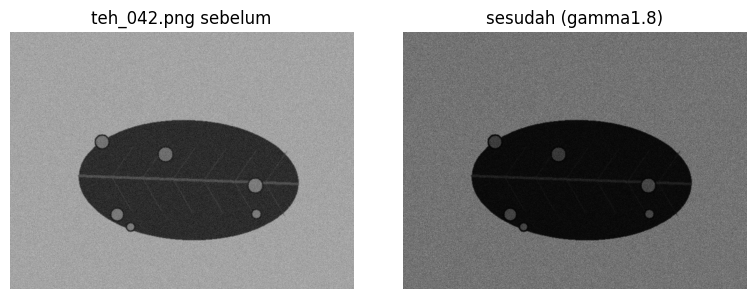

gelap           teh_022.png: gamma1.8   KB sebelum=2.58 sesudah=3.63


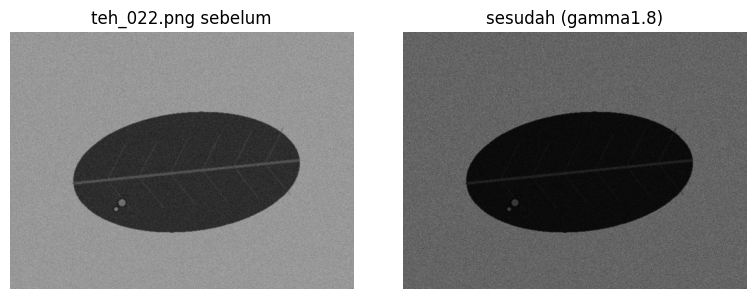

terang          teh_043.png: gamma1.8   KB sebelum=3.39 sesudah=3.66


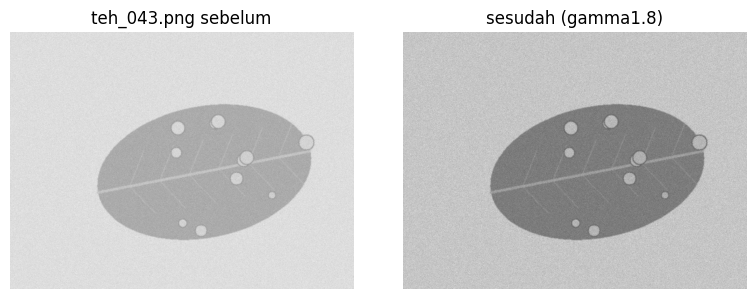

terang          teh_023.png: gamma1.8   KB sebelum=1.82 sesudah=1.99


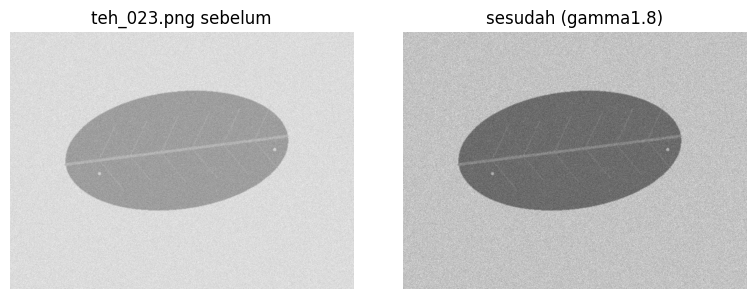

kontras_rendah  teh_044.png: regang     KB sebelum=2.17 sesudah=2.34


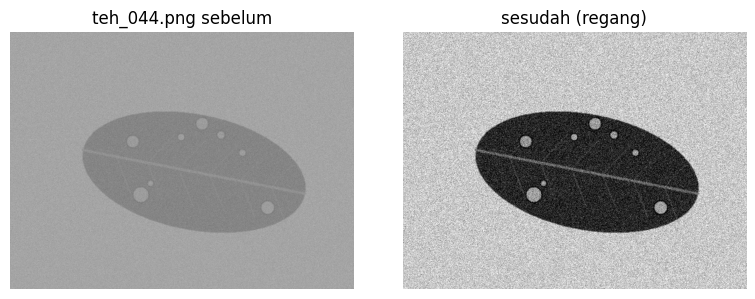

kontras_rendah  teh_024.png: regang     KB sebelum=1.31 sesudah=1.41


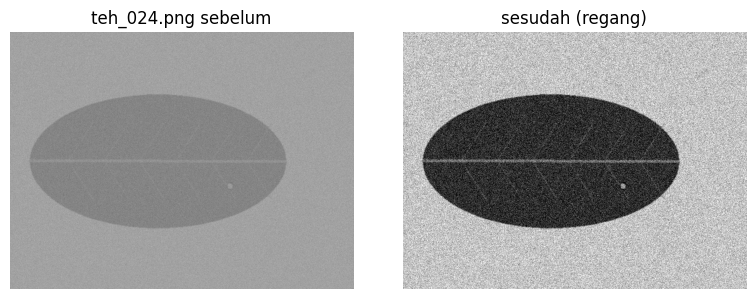

bayangan        teh_045.png: gamma1.8   KB sebelum=1.77 sesudah=2.11


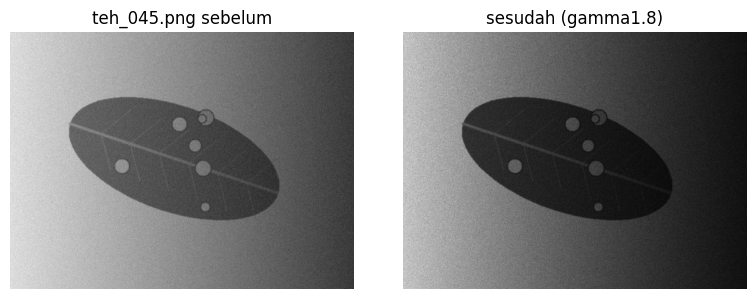

bayangan        teh_025.png: gamma1.8   KB sebelum=1.27 sesudah=1.45


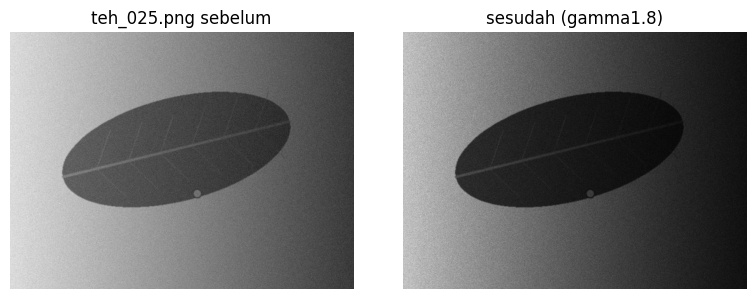

In [128]:
def kandidat(g):
    r1, r2 = np.percentile(g, (2, 98))
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
    return {"asli": g,
            "gamma0.5": cv2.LUT(g, gamma_lut(0.5)),
            "gamma0.7": cv2.LUT(g, gamma_lut(0.7)),
            "gamma1.5": cv2.LUT(g, gamma_lut(1.5)),
            "gamma1.8": cv2.LUT(g, gamma_lut(1.8)),
            "regang": np.clip((g - r1) / (r2 - r1) * 255, 0, 255).astype(np.uint8),
            "ekualisasi": cv2.equalizeHist(g),
            "CLAHE": clahe.apply(g)}

pasangan = {"gelap": ("teh_042.png", "teh_022.png"),
            "terang": ("teh_043.png", "teh_023.png"),
            "kontras_rendah": ("teh_044.png", "teh_024.png"),
            "bayangan": ("teh_045.png", "teh_025.png")}

# 1) uji semua metode pada 8 citra
baris = []
for kond, (nb, nr) in pasangan.items():
    for nm in (nb, nr):
        im = baca(f"../data/sintetis/citra/{nm}")
        m_d = cv2.imread(f"../data/sintetis/mask_daun/{nm}", 0)
        m_b = cv2.imread(f"../data/sintetis/mask_bercak/{nm}", 0)
        g0 = cv2.cvtColor(im, cv2.COLOR_BGR2GRAY)
        for met, c in kandidat(g0).items():
            baris.append([kond, nm, met, kontras_bercak(c, m_d, m_b)])
uji = pd.DataFrame(baris, columns=["kondisi", "citra", "metode", "KB"])
uji.pivot_table(index=["kondisi", "citra"], columns="metode",
                values="KB").round(2).to_csv("../hasil/b3_uji_metode.csv")

# 2) rerata KB dua citra per kondisi, lalu usulan metode terbaik (selain "asli")
rata = uji.groupby(["kondisi", "metode"]).KB.mean().unstack().round(2)
print(rata)
PILIHAN = rata.drop(columns="asli").idxmax(axis=1).to_dict()
print("\nUsulan metode per kondisi:", PILIHAN)

# 3) terapkan dan tampilkan sebelum-sesudah
for kond, (nb, nr) in pasangan.items():
    for nm in (nb, nr):
        im = baca(f"../data/sintetis/citra/{nm}")
        m_d = cv2.imread(f"../data/sintetis/mask_daun/{nm}", 0)
        m_b = cv2.imread(f"../data/sintetis/mask_bercak/{nm}", 0)
        g0 = cv2.cvtColor(im, cv2.COLOR_BGR2GRAY)
        g1 = kandidat(g0)[PILIHAN[kond]]
        print(f"{kond:15s} {nm}: {PILIHAN[kond]:10s} KB sebelum={kontras_bercak(g0, m_d, m_b):.2f} "
              f"sesudah={kontras_bercak(g1, m_d, m_b):.2f}")
        tampil([g0, g1], [f"{nm} sebelum", f"sesudah ({PILIHAN[kond]})"], ukuran=(8, 3))
        plt.savefig(f"../hasil/b3_perbaikan_{kond}_{nm[:-4]}.png"); plt.show()

gelap           teh_042.png: gamma0.5   KB sebelum=4.33 sesudah=3.38


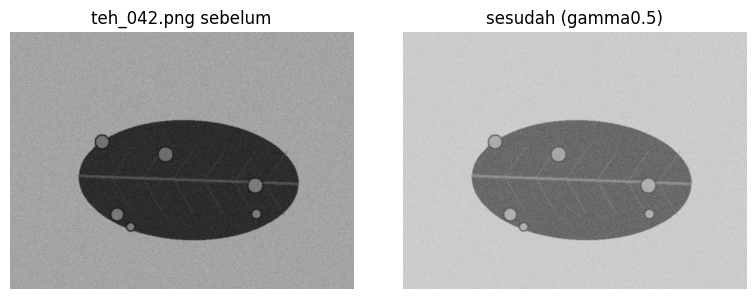

gelap           teh_022.png: gamma0.5   KB sebelum=2.58 sesudah=2.01


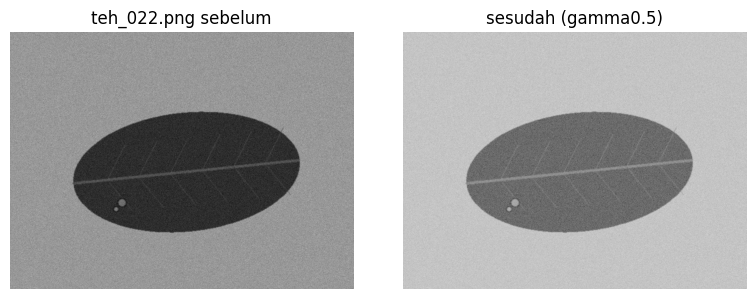

terang          teh_043.png: gamma1.8   KB sebelum=3.39 sesudah=3.66


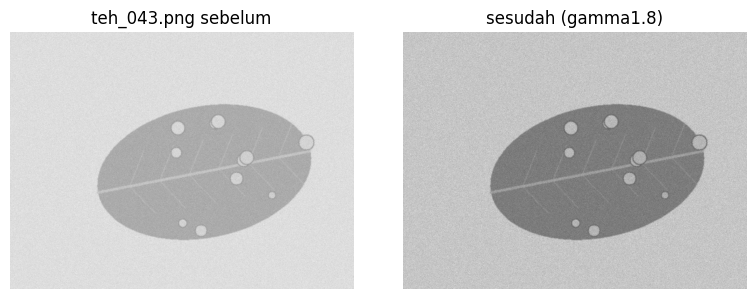

terang          teh_023.png: gamma1.8   KB sebelum=1.82 sesudah=1.99


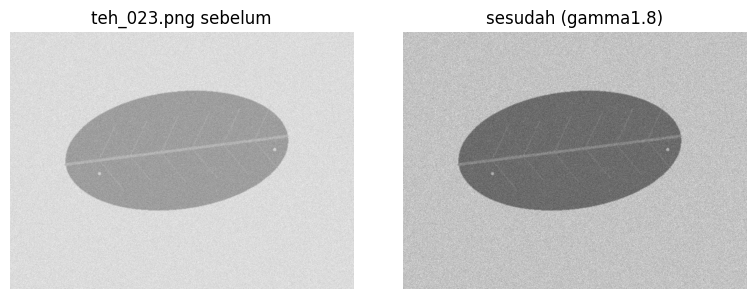

kontras_rendah  teh_044.png: regang     KB sebelum=2.17 sesudah=2.34


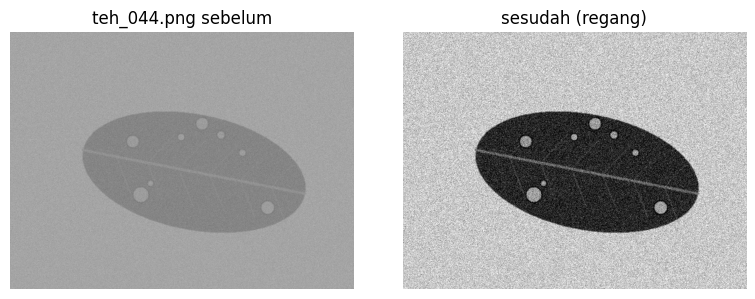

kontras_rendah  teh_024.png: regang     KB sebelum=1.31 sesudah=1.41


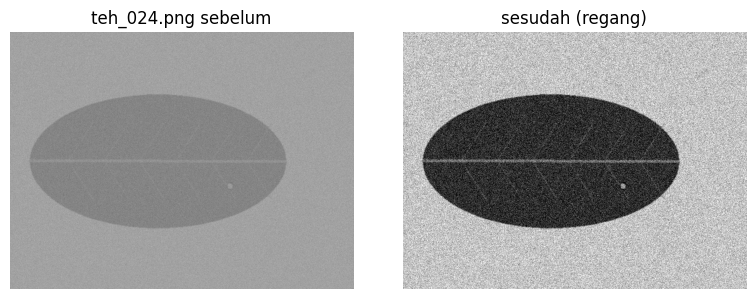

bayangan        teh_045.png: CLAHE      KB sebelum=1.77 sesudah=2.18


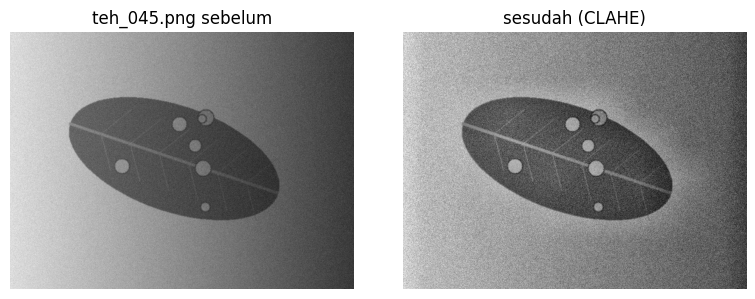

bayangan        teh_025.png: CLAHE      KB sebelum=1.27 sesudah=0.99


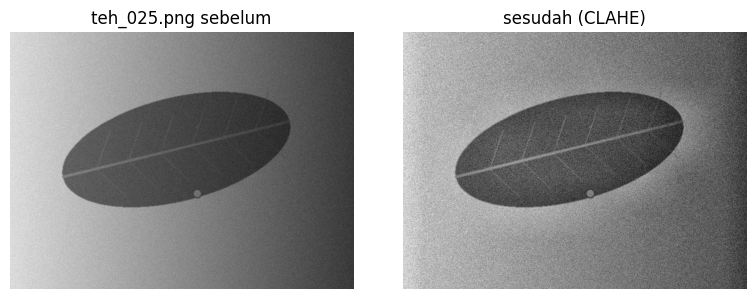

In [129]:
PILIHAN = {"gelap": "gamma0.5", "terang": "gamma1.8",
           "kontras_rendah": "regang", "bayangan": "CLAHE"}

for kond, (nb, nr) in pasangan.items():
    for nm in (nb, nr):
        im = baca(f"../data/sintetis/citra/{nm}")
        m_d = cv2.imread(f"../data/sintetis/mask_daun/{nm}", 0)
        m_b = cv2.imread(f"../data/sintetis/mask_bercak/{nm}", 0)
        g0 = cv2.cvtColor(im, cv2.COLOR_BGR2GRAY)
        g1 = kandidat(g0)[PILIHAN[kond]]
        print(f"{kond:15s} {nm}: {PILIHAN[kond]:10s} "
              f"KB sebelum={kontras_bercak(g0, m_d, m_b):.2f} "
              f"sesudah={kontras_bercak(g1, m_d, m_b):.2f}")
        tampil([g0, g1], [f"{nm} sebelum", f"sesudah ({PILIHAN[kond]})"], ukuran=(8, 3))
        plt.savefig(f"../hasil/b3_perbaikan_{kond}_{nm[:-4]}.png"); plt.show()